In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch
torch.set_default_tensor_type(torch.DoubleTensor)
torch.set_default_dtype(torch.float64)

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem2
import optimiser_problem2_new_new as optimiser_problem2
from math import factorial
import pickle

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [2]:
sigma_s = 1e-1
b1 = 1.2e-1 #1e-3
b3 = 1e-1 #2
b2 = 2
sigma2 = 2

params = {'b0': 1, 'b1': b1, 'b2': b2, 'b3': b3,
          'sigma0': 1, 'sigma2': sigma2, 'k': 1e-3, 
          'theta1': 10, 'theta2': 1e-2, 'S0': 100, 'Q0': 10, 'X0': 0, 
          'T': 0.10, 'Nt': 1_000}

env = problem2.environment(**params)

In [3]:
np.random.seed(20250524)
dim = 2
order = 7
num_elements = dim**(order+1) - 1

with open('W_sig_1.pkl', 'rb') as f:
    W_sig = pickle.load(f)
    f.close()

# with open('F_optimised_problem2.pkl', 'rb') as f:
#     F = pickle.load(f)
#     f.close()

F = 2*np.ones(num_elements)
    
#env = problem2.environment(**params)
optimiser_1 = optimiser_problem2.Optimiser(env, W_sig, order = order)
F = ta.sig_to_tensor(F, dim, order)

In [4]:
F

Tensor([2.0, [2.0, 2.0], [[2.0, 2.0], [2.0, 2.0]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]]], [[[[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]]], [[[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]]]], [[[[[[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]], [[[2.0, 2.0], [2.0, 2.0]], [[2.0, 2.0], [2.0, 2.0]]]], [[[[

In [5]:
# Define tensor algebra constant
e0 = ta.word((), dim)
e1 = ta.word((0,), dim)
e2 = ta.word((1,), dim)

# Defining the representation of S and \hat{\alpha} in terms of the innovation process
trunc_lev = order

LG = e1*env.b2 + F*env.b3*e1 + e2*env.sigma2
neg_LG = -LG

max_iter = F.order
M_max = F.order

exp_LG = LG.exp(MAX_ITER = max_iter, MAX_LEVEL = trunc_lev, METHOD = '2')
exp_neg_LG = neg_LG.exp(MAX_ITER = max_iter, MAX_LEVEL = trunc_lev, METHOD = '2')

LF = exp_LG*env.S0
term1 = (exp_neg_LG.shuffle(e0*env.b0 + F*env.b1, max_order = M_max))*e1
LF += exp_LG.shuffle(term1, max_order = M_max)
term2 = (exp_neg_LG*env.sigma0)*e2
LF += exp_LG.shuffle(term1, max_order = M_max)

LF = LF.truncate(trunc_lev)
    
optimiser_1.LF = LF

In [6]:
LF

Tensor([100.0, [222.48000000000005, 200.0], [[509.93600000000015, 444.9600000000001], [460.4800000000001, 400.0]], [[[1231.3312, 1019.8720000000003], [1083.8880000000001, 889.9200000000002]], [[1118.0320000000004, 920.9600000000002], [980.4800000000001, 800.0]]], [[[[3168.858240000001, 2462.6624], [2673.1616000000004, 2039.7440000000006]], [[2817.100800000001, 2167.7760000000003], [2360.784, 1779.8400000000004]]], [[[2895.3216000000007, 2236.0640000000008], [2432.1760000000004, 1841.9200000000003]], [[2566.2240000000006, 1960.9600000000003], [2140.4799999999996, 1600.0]]]], [[[[[8766.940288000005, 6337.716480000002], [7042.952320000003, 4925.3248]], [[7534.7609600000005, 5346.323200000001], [5978.780800000001, 4079.488000000001]]], [[[7874.163200000003, 5634.201600000002], [6282.566400000001, 4335.552000000001]], [[6734.995200000002, 4721.568], [5301.552, 3559.6800000000007]]]], [[[[8063.0105600000015, 5790.643200000001], [6448.940800000002, 4472.1280000000015]], [[6908.198400000001, 4

In [7]:
# with open('LF_experiment_1.pkl', 'wb') as f:
#     pickle.dump(LF.flatten(), f)
#     f.close()

In [8]:
LF_max_element = np.array([float(LF.value[i].flatten().abs().max()) for i in range(trunc_lev+1)])

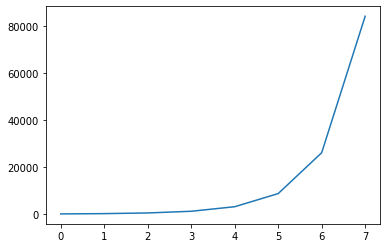

In [9]:
plt.plot(LF_max_element)

In [10]:
lev = np.array([i for i in range(trunc_lev+1)])

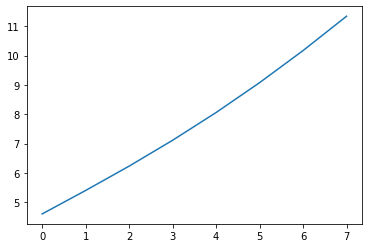

In [11]:
plt.plot(np.log(LF_max_element))

In [12]:
np.log(LF_max_element)

array([ 4.60517019,  5.40483721,  6.23428523,  7.11585114,  8.06112663,
        9.07874314, 10.17281297, 11.34295601])

In [13]:
np.log(LF_max_element[1]) - np.log(LF_max_element[0])

0.7996670239376176

In [14]:
np.e**0.7080456452219117

2.0300199999999995

In [15]:
LF_max_element

array([  100.        ,   222.48      ,   509.936     ,  1231.3312    ,
        3168.85824   ,  8766.940288  , 26181.6212736 , 84369.05866752])

In [16]:
np.random.seed(456)
trunc_lev = 4
trunc_lev_1 = 4
n_epochs = 20
lr = 10

#optimiser_1.train_sgd(n_epochs, lr = lr, trunc_lev_s = trunc_lev, method='SGD')

#F = optimiser_1.F

strag_sig = problem2.sig_strag_dot(F, order = order)

In [17]:
# with open('F_optimised_problem2.pkl', 'wb') as f:
#     pickle.dump(F.flatten(), f)
#     f.close()

In [18]:
np.random.seed(123)

nsims = 10

env.simulate(nsims, strag_sig)

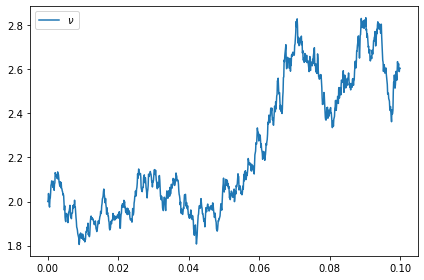

In [19]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
#plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
print(f'Performance criterion\nSig: {env.run_crit[-1,:].mean()}')
print(f'Wealth\nSig: {env.wealth[-1,:].mean()}')

Performance criterion
Sig: 384.4437646935516
Wealth
Sig: 1626.1128272569563


In [21]:
optimiser_1.value_fn(F.flatten(), trunc_lev_s = trunc_lev)

-366.20927413859795

In [22]:
# f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
# f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
# f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = order)

#LF = optimiser_1.LF
p_perf = optimiser_1.p_perf

f_s_sig = problem2.sig_strag_dot(LF, order = trunc_lev)
f_perf_crit = problem2.sig_strag_dot(p_perf, order = order)

S_sig = np.zeros((env.Nt+1,nsims))
perf_hist = np.zeros((env.Nt+1,nsims))

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(env.Nt+1):
    S_sig[it,:] = f_s_sig(env,it)
    perf_hist[it,:] = f_perf_crit(env,it)
    #S_sig[it,:] = strag_sig(env,it)

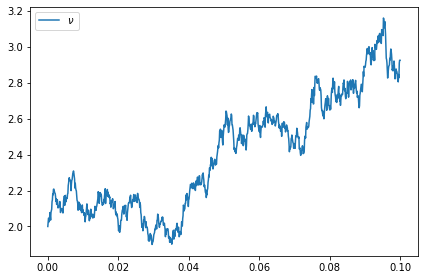

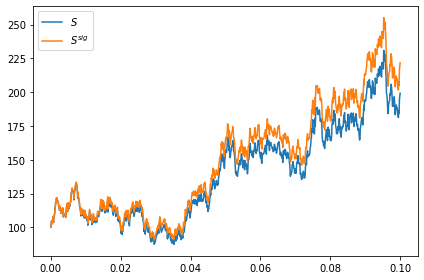

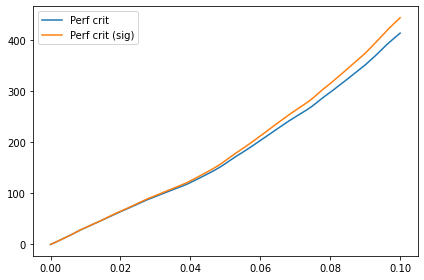

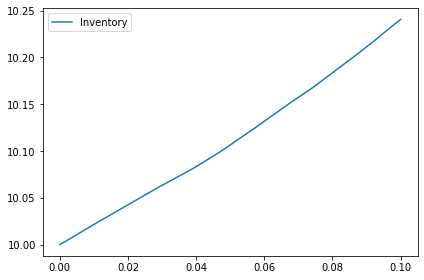

In [23]:
nsim = 8

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.S[:,nsim], label=r'$S$')
plt.plot(env.timesteps, S_sig[:,nsim], label=r'$S^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps[:], perf_hist[:,nsim], label=r'Perf crit (sig)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.Q[:,nsim], label=r'Inventory')
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
env.Q

array([[10.        , 10.        , 10.        , ..., 10.        ,
        10.        , 10.        ],
       [10.0002    , 10.0002    , 10.0002    , ..., 10.0002    ,
        10.0002    , 10.0002    ],
       [10.00039786, 10.00040202, 10.00040059, ..., 10.00039916,
        10.00040257, 10.00039829],
       ...,
       [10.19226458, 10.24817003, 10.2221292 , ..., 10.18286219,
        10.24007638, 10.24168806],
       [10.19247578, 10.24842107, 10.22238806, ..., 10.18298795,
        10.24036733, 10.24196095],
       [10.19268763, 10.24867377, 10.22264842, ..., 10.18311359,
        10.24065989, 10.2422324 ]])